In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# <center> Research Questions <center>

In [2]:
# loading in data
final_data = os.listdir('/Users/marcomaluf/Desktop/Unfinished Projects/paper/final_data')
formatted_data = os.listdir('/Users/marcomaluf/Desktop/Unfinished Projects/paper/formatted_data')
final_data.sort()
formatted_data.sort()

final_data_dfs = [pd.read_csv(f'/Users/marcomaluf/Desktop/Unfinished Projects/paper/final_data/{csv}').drop(columns=['Unnamed: 0']) for csv in final_data]
formatted_data_dfs = [pd.read_csv(f'/Users/marcomaluf/Desktop/Unfinished Projects/paper/formatted_data/{csv}').drop(columns=['Unnamed: 0']) for csv in formatted_data]

## <center> General Questions/Analyses <center>

In [ ]:
"""
NOTE:
- add the mean value of `hit_team_no` to this for mean posession throughout the play 
    -> attacking team possession, defending team posession
"""

In [ ]:
all_data = []
for final_df, formatted_df in zip(final_data_dfs, formatted_data_dfs):
    temp = pd.concat([formatted_df, final_df.drop(columns=['pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z', 'label'])], axis=1)
    all_data.append(temp)
all_data_df = pd.concat(all_data, axis=0)

xg_characteristics = {
    'dist_to_goal': [],
    'angle_to_goal': [],
    'players_btwn_ball_and_goal': [],
    'players_within_400_of_ball': [],
    'attacking_team_dist_to_ball': [], # mean distance to ball
    'defending_team_dist_to_ball': [], # mean distance to ball
    'attacking_team_dist_bw_states': [], # mean distance between states
    'defending_team_dist_bw_states': [], # mean distance between states
    'attacking_team_dist_bw_teammates': [], # mean distance bw teammates
    'defending_team_dist_bw_teammates': [] # mean distance bw teammates
}

def distance_3d(v1, v2):
    d = np.power(v1-v2, 2)
    d = np.sum(d, axis=1)

    distance = np.sqrt(d)
    
    return distance

blue_team_dists_to_ball = [15, 24, 33]
blue_team_positions = [7,8,9, 16,17,18, 25,26,27]
orange_team_dists_to_ball = [42, 51, 60]
orange_team_positions = [34,35,36, 43,44,45, 52,53,54]

for i in range(0,len(all_data_df),64):

    half = 1 if all_data_df.pos_y.iloc[(i+64)-1] > 0 else 0
    if half == 1:
        attacking_team_dist_to_ball = all_data_df.iloc[i:i+64, blue_team_dists_to_ball]
        defending_team_dist_to_ball = all_data_df.iloc[i:i+64, orange_team_dists_to_ball]

        attacking_team_state = all_data_df.team1_cluster.iloc[i:i+64]
        defending_team_state = all_data_df.team2_cluster.iloc[i:i+64]

        attacking_team_positions = all_data_df.iloc[i:i+64, blue_team_positions]
        defending_team_positions = all_data_df.iloc[i:i+64, orange_team_positions]
    else:
        attacking_team_dist_to_ball = all_data_df.iloc[i:i+64, orange_team_dists_to_ball]
        defending_team_dist_to_ball = all_data_df.iloc[i:i+64, blue_team_dists_to_ball]

        attacking_team_state = all_data_df.team2_cluster.iloc[i:i+64]
        defending_team_state = all_data_df.team1_cluster.iloc[i:i+64]

        attacking_team_positions = all_data_df.iloc[i:i+64, orange_team_positions]
        defending_team_positions = all_data_df.iloc[i:i+64, blue_team_positions]

    mean_attacking_team_dist_to_ball = np.mean(np.mean(attacking_team_dist_to_ball, axis=0))
    mean_defending_team_dist_to_ball = np.mean(np.mean(defending_team_dist_to_ball, axis=0))

    attacking_team_dist_bw_states = np.mean(np.sqrt(np.power(attacking_team_state.values-all_data_df.ball_state.iloc[i:i+64].values, 2)))
    defending_team_dist_bw_states = np.mean(np.sqrt(np.power(defending_team_state.values-all_data_df.ball_state.iloc[i:i+64].values, 2)))

    # dist bw p1/2
    attacking_p1p2_dist = distance_3d(attacking_team_positions.iloc[:,0:3].values, attacking_team_positions.iloc[:,3:6].values)
    attacking_p1p2_dist = attacking_p1p2_dist[(attacking_p1p2_dist < 8000)] # removes distances from players who were demo'd, masked value of -999999 skews results
    defending_p1p2_dist = distance_3d(defending_team_positions.iloc[:,0:3].values, defending_team_positions.iloc[:,3:6].values)
    defending_p1p2_dist = defending_p1p2_dist[(defending_p1p2_dist < 8000)] # removes distances from players who were demo'd, masked value of -999999 skews results

    # dist bw p1/3
    attacking_p1p3_dist = distance_3d(attacking_team_positions.iloc[:,0:3].values, attacking_team_positions.iloc[:,6:9].values)
    attacking_p1p3_dist = attacking_p1p3_dist[(attacking_p1p3_dist < 8000)] # removes distances from players who were demo'd, masked value of -999999 skews results
    defending_p1p3_dist = distance_3d(defending_team_positions.iloc[:,0:3].values, defending_team_positions.iloc[:,6:9].values)
    defending_p1p3_dist = defending_p1p3_dist[(defending_p1p3_dist < 8000)] # removes distances from players who were demo'd, masked value of -999999 skews results

    # dist bw p2/3
    attacking_p2p3_dist = distance_3d(attacking_team_positions.iloc[:,3:6].values, attacking_team_positions.iloc[:,6:9].values)
    attacking_p2p3_dist = attacking_p2p3_dist[(attacking_p2p3_dist < 8000)] # removes distances from players who were demo'd, masked value of -999999 skews results
    defending_p2p3_dist = distance_3d(defending_team_positions.iloc[:,3:6].values, defending_team_positions.iloc[:,6:9].values)
    defending_p2p3_dist = defending_p2p3_dist[(defending_p2p3_dist < 8000)] # removes distances from players who were demo'd, masked value of -999999 skews results

    # mean dist bw team
    attacking_team_dist_bw_teammates = np.mean([np.mean(attacking_p1p2_dist), np.mean(attacking_p1p3_dist), np.mean(attacking_p2p3_dist)])
    defending_team_dist_bw_teammates = np.mean([np.mean(defending_p1p2_dist), np.mean(defending_p1p3_dist), np.mean(defending_p2p3_dist)])

    xg_characteristics['dist_to_goal'].append(all_data_df.iloc[i:i+64].dist_to_goal.mean())
    xg_characteristics['angle_to_goal'].append(all_data_df.iloc[i:i+64].angle_to_goal.mean())
    xg_characteristics['players_btwn_ball_and_goal'].append(all_data_df.iloc[i:i+64].players_btwn_ball_and_goal.mean())
    xg_characteristics['players_within_400_of_ball'].append(all_data_df.iloc[i:i+64].players_within_400_of_ball.mean())
    xg_characteristics['attacking_team_dist_to_ball'].append(mean_attacking_team_dist_to_ball)
    xg_characteristics['defending_team_dist_to_ball'].append(mean_defending_team_dist_to_ball)
    xg_characteristics['attacking_team_dist_bw_states'].append(attacking_team_dist_bw_states)
    xg_characteristics['defending_team_dist_bw_states'].append(defending_team_dist_bw_states)
    xg_characteristics['attacking_team_dist_bw_teammates'].append(attacking_team_dist_bw_teammates)
    xg_characteristics['defending_team_dist_bw_teammates'].append(defending_team_dist_bw_teammates)

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [4]:
all_xGs = [all_data_df.xG.iloc[i] for i in range(0,len(all_data_df),64)]
all_labels = [all_data_df.label.iloc[i] for i in range(0,len(all_data_df),64)]
all_xG_stats_df = pd.DataFrame(xg_characteristics)
all_xG_stats_df.loc[:,'xG'] = all_xGs
all_xG_stats_df.loc[:,'label'] = all_labels

In [5]:
all_xG_stats_df

,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal,players_within_400_of_ball,attacking_team_dist_to_ball,defending_team_dist_to_ball,attacking_team_dist_bw_states,defending_team_dist_bw_states,attacking_team_dist_bw_teammates,defending_team_dist_bw_teammates,xG,label
0,0.644794,0.165650,0.00000,0.244792,2090.691867,3657.342268,0.053177,0.373515,2719.818904,5395.116016,0.003,0
1,0.630712,0.136126,0.00000,0.104167,2695.004962,2054.207588,0.443994,0.366092,2456.392010,2515.025821,0.016,0
2,0.744402,0.112178,0.43750,0.093750,1983.036105,3303.445072,0.320867,0.485942,2908.196136,2679.941081,0.001,0
3,0.660375,0.081815,0.00000,0.114583,4404.353119,2680.103059,0.484677,0.139354,5397.875253,3296.089213,0.003,0
4,0.502807,0.244924,0.00000,0.161458,2104.487934,3191.160986,0.211423,0.412405,3134.557090,4969.305253,0.892,1
...,...,...,...,...,...,...,...,...,...,...,...,...
620,0.445742,0.177591,0.00000,0.432292,2491.764398,1936.664354,0.229791,0.050146,3717.707864,3303.150690,0.865,0
621,0.325611,0.360316,0.00000,0.000000,3589.537331,3837.462738,0.401296,0.184169,5049.745837,4005.914561,0.912,1
622,0.516302,0.152125,0.00000,0.213542,2087.090964,2142.616533,0.403890,0.405033,2461.301236,2952.980101,0.094,0
623,0.260198,0.360199,0.03125,0.062500,2840.870328,1879.663689,0.462835,0.340122,3211.105324,1802.209376,0.836,1


In [6]:
all_xG_stats_df.drop(columns=['label']).corr().loc['xG']

dist_to_goal                       -0.626722
angle_to_goal                       0.561711
players_btwn_ball_and_goal          0.107184
players_within_400_of_ball         -0.000531
attacking_team_dist_to_ball        -0.108082
defending_team_dist_to_ball        -0.165603
attacking_team_dist_bw_states      -0.014079
defending_team_dist_bw_states      -0.030948
attacking_team_dist_bw_teammates   -0.079178
defending_team_dist_bw_teammates   -0.138911
xG                                  1.000000
Name: xG, dtype: float64

Getting the initial xyz position of the ball for each shot. If the shot ends on a different half than it started on, reflect the shot along the x-axis (multiply pos_y by -1):

In [53]:
starting_positions = {
    'start_x': [],
    'start_y': [],
    'start_z': []
}
for i in range(0,len(all_data_df),64):
    start_y = all_data_df.pos_y.iloc[i]
    end_y = all_data_df.pos_y.iloc[i+63]
    if np.sign(start_y) != np.sign(end_y):
        start_y *= -1
    starting_positions['start_x'].append(all_data_df.pos_x.iloc[i])
    starting_positions['start_y'].append(start_y)
    starting_positions['start_z'].append(all_data_df.pos_z.iloc[i])

In [56]:
all_xG_stats_df.insert(0,'start_x',starting_positions['start_x'])
all_xG_stats_df.insert(1,'start_y',starting_positions['start_y'])
all_xG_stats_df.insert(2,'start_z',starting_positions['start_z'])
all_xG_stats_df

,start_x,start_y,start_z,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal,players_within_400_of_ball,attacking_team_dist_to_ball,defending_team_dist_to_ball,attacking_team_dist_bw_states,defending_team_dist_bw_states,attacking_team_dist_bw_teammates,defending_team_dist_bw_teammates,xG,label
0,2643.65,1757.71,915.41,0.644794,0.165650,0.00000,0.244792,2090.691867,3657.342268,0.053177,0.373515,2719.818904,5395.116016,0.003,0
1,3783.62,-3781.92,827.59,0.630712,0.136126,0.00000,0.104167,2695.004962,2054.207588,0.443994,0.366092,2456.392010,2515.025821,0.016,0
2,3441.00,-3335.57,1003.76,0.744402,0.112178,0.43750,0.093750,1983.036105,3303.445072,0.320867,0.485942,2908.196136,2679.941081,0.001,0
3,-3689.19,2991.40,593.95,0.660375,0.081815,0.00000,0.114583,4404.353119,2680.103059,0.484677,0.139354,5397.875253,3296.089213,0.003,0
4,-3515.06,3623.24,1402.08,0.502807,0.244924,0.00000,0.161458,2104.487934,3191.160986,0.211423,0.412405,3134.557090,4969.305253,0.892,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
620,-141.08,423.73,187.88,0.445742,0.177591,0.00000,0.432292,2491.764398,1936.664354,0.229791,0.050146,3717.707864,3303.150690,0.865,0
621,-2074.54,-145.07,519.17,0.325611,0.360316,0.00000,0.000000,3589.537331,3837.462738,0.401296,0.184169,5049.745837,4005.914561,0.912,1
622,-1781.50,859.77,1488.12,0.516302,0.152125,0.00000,0.213542,2087.090964,2142.616533,0.403890,0.405033,2461.301236,2952.980101,0.094,0
623,3834.44,3803.76,279.55,0.260198,0.360199,0.03125,0.062500,2840.870328,1879.663689,0.462835,0.340122,3211.105324,1802.209376,0.836,1


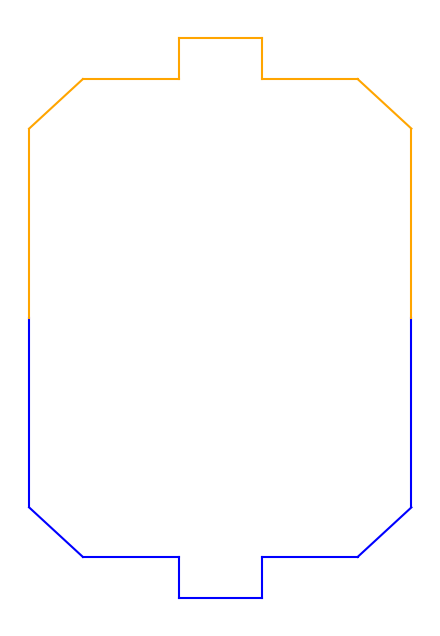

In [ ]:
import matplotlib.pyplot as plt

LINES = [   # blue half
            [(4096,0),(4096,-4058)],
            [(-2944,-5120),(-893,-5120)],
            [(2944,-5120),(893,-5120)],
            [(-4096,0),(-4096,-4058)],
            [(2944,-5120),(4096,-4058)],
            [(-2944,-5120),(-4096,-4058)],
            [(893,-6000),(-893,-6000)],
            [(893,-6000),(893,-5120)],
            [(-893,-6000),(-893,-5120)],
            # orange half
            [(4096,0),(4096,4058)],
            [(-2944,5120),(-893,5120)],
            [(2944,5120),(893,5120)],
            [(-4096,0),(-4096,4058)],
            [(2944,5120),(4096,4058)],
            [(-2944,5120),(-4096,4058)],
            [(893,6000),(-893,6000)],
            [(893,6000),(893,5120)],
            [(-893,6000),(-893,5120)],
        ]

COLORS = ['blue']*9 + ['orange']*9

fig, ax = plt.subplots(figsize=(12,8))
for line, color in zip(LINES, COLORS):
    xs = [line[0][0], line[1][0]]
    ys = [line[0][1], line[1][1]]
    ax.plot(xs, ys, color=color)
ax.set_aspect('equal')
ax.axis('off')
ax.set_facecolor('none')
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

## <center> What makes a shot have a high xG? A low xG? <center>

<center> Is the model capturing meaningful differences between "good" and "bad" shots? <center>

For the purposes of this analysis, a shot with a high xG is defined as:

$$
\text{xG}_{\text{high}} := \text{xG} \geq 0.65,
$$

and a shot with a low xG is defined as:

$$
\text{xG}_{\text{low}} := \text{xG} \leq 0.35.
$$

Work-flow idea:
1. concat/stack all the data in the array top-down
2. for each 64 segment, aggregate the "shot characteristics" together in separate arrays
    - shot attributes
        - (scaled) averages/medians of model features
            - under this, average distances between the ball_state, the scoring team's state, and the defending team's state
        - where on the field the shot was taken (half, zone)
        - distances between teammates (both attackers and defenders)
        - other...

    and then make then into dataframes and append the shot's xG for easier analysis
3. make plots (first plot should be box plots of all the aggregations for population-wide distributions)
4. do some tests to compare the distributions of the characteristics between high and low xG shots, like some hypothesis tests, to see if there is a statistically significant difference
5. Take correlations between certain variables (e.g. correlations bw distance bw states for each team and the xG, ...)

In [40]:
high_xG_stats_df = all_xG_stats_df[all_xG_stats_df.xG >= 0.65]
high_xG_stats_df.label.value_counts()

label
1    97
0    92
Name: count, dtype: int64

In [41]:
low_xG_stats_df = all_xG_stats_df[all_xG_stats_df.xG <= 0.35]
low_xG_stats_df.label.value_counts()

label
0    272
1     33
Name: count, dtype: int64

In [45]:
all_data_df.index

Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1590, 1591, 1592, 1593, 1594, 1595, 1596, 1597, 1598, 1599],
      dtype='int64', length=40000)

## <center> What are the similarities and differences for non-goals with high xG compared to goals? <center>

## <center> How well do the game state variables encode the states of the teams and the ball? <center>

<center> (might be answered in the high xG analysis section but we'll see. maybe do this first and then see if I should even bother looking at it for that analysis?) <center>

<center> To help answer this, take the code from step 5 in preprocessing notebook to get the Eigenvector dfs and compare to positional plots. <center>